# Cooperative Inference Scheduling + KV-Cache Replacement for Agentic Workloads

**Objective:** p99 *inter-turn* TTFT (tool return → first token of the next LLM call). Secondary: mean E2E, throughput, PCIe traffic.

This notebook explains, with figures, what we found when we (1) dissected the existing simulator, (2) designed a policy in which the
admission scheduler and the KV replacement policy share information, and (3) evaluated it against the existing baselines with an ablation.

**TL;DR**

| | finding |
|---|---|
| Where p99 comes from today | ≥ 99% **queueing**. PCIe reload stall < 0.25 s, prefill step < 0.25 s for the slowest 1% of turns. |
| Why the queue tail is so long | Admission walks conversations in **index order** and stops at the first one that does not fit → late conversations starve. |
| Proposed policy | age-guarded soft cap + backfill (scheduler) and queue-aware Belady eviction + prefetch (replacement). |
| Result | p99 TTFT **138 → 21 s (48 GB)** and **153 → 11 s (64 GB)** vs Cap Oracle; lower on 6/6 held-out seeds; mean E2E 3–8 % better; throughput slightly higher. |
| Where the gain comes from | **Scheduling.** Replacement-side cooperation adds ~nothing to p99 on this hardware model (reloads are ~0.1 s). |
| Costs | p50 +1.5 s at 48 GB; 2–5× more PCIe traffic than the capped baselines (fair service rotates all conversations through HBM). |

Code: `sim/coop_sim.py` (policy + measurement), `sim/run_coop_experiments.py` (sweeps), `sim/analyze_coop.py` (tables).
Existing baselines in `sim/paged_vs_oracle.py` are **unchanged**.

In [1]:
import os, sys, json, gzip
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ProcessPoolExecutor

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir(os.path.abspath(".."))
sys.path.insert(0, os.getcwd())

from sim.scheduler_sim import CostModel, KVGeometry, PCIeLink

# ---- plotting style + fixed entity colors (categorical slots in fixed order) ----
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": SURF, "axes.facecolor": SURF, "legend.frameon": False,
                     "axes.titlelocation": "left"})
PAL = {"Coop (proposed)": "#2a78d6", "Cap Oracle (300K)": "#eb6834", "Cap LRU (300K)": "#1baf7a",
       "Uncapped Oracle": "#eda100", "Uncapped LRU": "#e87ba4"}
MAIN = list(PAL)
SEEDS = [1, 2, 3, 4, 5, 42]          # held-out evaluation seeds (Coop knobs were tuned on 100-101)
HBMS = [48.0, 64.0]

S = json.load(open("results/coop/summary.json"))
RAW = json.load(gzip.open("results/coop/ttft_rows.json.gz", "rt"))   # per turn: total, queue, stall, svc, own_prefill

def runs(exp, label, hbm, rate=0.15):
    ks = [f"{exp}|{label}|{hbm:.0f}|{rate}|{s}" for s in SEEDS]
    return [S[k] for k in ks if k in S], [np.array(RAW[k]) for k in ks if k in RAW]

def mean_of(exp, label, hbm, f, rate=0.15):
    return float(np.mean([f(s) for s in runs(exp, label, hbm, rate)[0]]))

def labels(exp):
    out = []
    for k in S:
        e, lab = k.split("|")[:2]
        if e == exp and lab not in out:
            out.append(lab)
    return out

cm = lambda key: (lambda s: s["coop_metrics"].get(key, 0.0))
print(f"{len(S)} simulation summaries loaded; experiments: {sorted({k.split('|')[0] for k in S})}")

492 simulation summaries loaded; experiments: ['ablation', 'capcheck', 'capsweep', 'dsweep', 'main', 'rate025']


---
## Part 1 — How the simulator works

The class chain is `Sim` (`sim/scheduler_sim.py`) → `PinSim` (`sim/pin_sim.py`) → `BaselineEvictionSim` (`sim/baseline_sim.py`)
→ the four policies in `sim/paged_vs_oracle.py`, plus `CappedConcurrencyMixin` for the capped variants.

### 1.1 Scheduling / admission
* Discrete-event loop (`Sim.advance_once`): handle due events, then **one continuous-batching step** over every PREFILL+DECODE request.
* Admission happens only in `_reconcile`, which fires on a **0.5 s epoch** and on a few reload events. A returning turn whose KV is still
  pinned waits for the next epoch → p50 TTFT has a ~0.5 s floor for every policy.
* `PinSim._vllm_reconcile → _admit_waiting → Sim._vllm_reconcile` walks `self.live` **in conversation-index order** and **`break`s at the
  first request that cannot be admitted** (no backfill). This is a static per-program priority, not per-turn FCFS.
* Caps (`CappedConcurrencyMixin`): `r_cap` = Σ resident tokens of active (PREFILL+DECODE) requests, `b_cap` = batch size; checked in
  `_admit_full` *before* any eviction. (`sjf=True` is dead code: nothing calls `_try_admit`.)

### 1.2 Replacement
* **Pinning:** with `pin_frac=1` a request keeps its KV in HBM across a tool call; eviction is lazy, only under pressure.
  Inactive KV therefore already stays in unused HBM.
* **Paged LRU / Paged Oracle:** evict only the deficit *tail blocks*. LRU picks the oldest `parked_at`; the Oracle picks the TOOL request with
  the furthest tool return τ (WAITING, then STALL, as fallback), and schedules a **JIT H2D reload** at τ − T_reload (EDF, block reservation).
* **Existing cooperation is weak and one-way:** Oracle admission checks that enough blocks are evictable; JIT reloads reserve blocks the
  scheduler then cannot use. Eviction never looks at the admission queue.

### 1.3 Hardware model
* Step time = `base + a_batch·B + a_resident·ΣR_active + a_prefill·P` (H100 fit below). **Only active KV costs decode time** — TOOL /
  WAITING KV is free. There is no separate HBM-bandwidth term; contention lives entirely in `a_resident`.
* PCIe: two independent FIFO channels (full duplex), calibrated 46.8 GiB/s D2H, 45.5 GiB/s H2D at 4 MiB blocks.
* Memory: a block pool (16 tokens × 128 KiB/token = 2 MiB per block); 48 GB ≈ 393K tokens.

base=16.0 ms  a_batch=0.319 ms/req  a_resident=2.15e-07 s/token  a_prefill=60.8 us/token  | KV 128 KiB/token


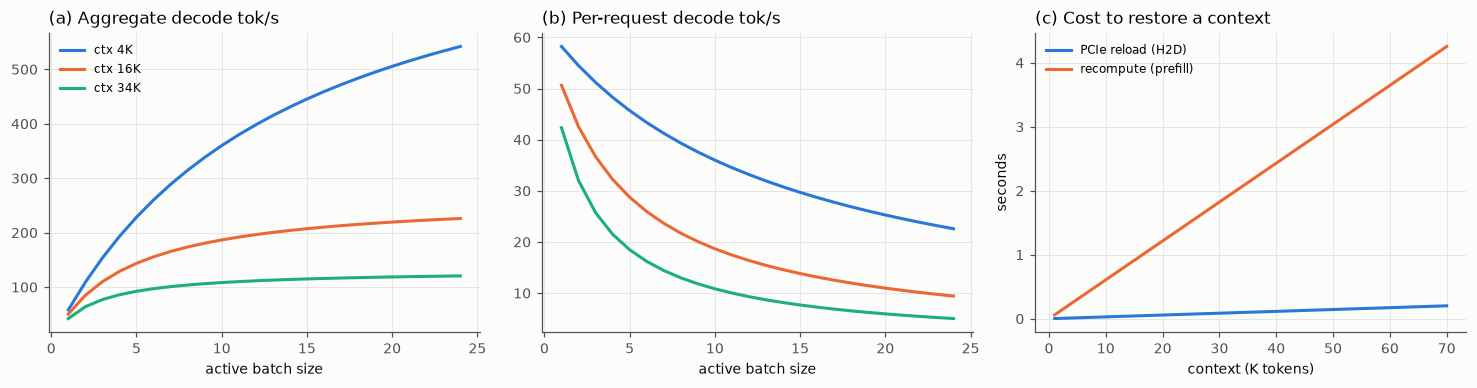

In [2]:
cost = CostModel.from_calibration("results/sim_costmodel_h100_0905b.json")
link = PCIeLink.from_calibration("results/sim_calibration.json")
geom = KVGeometry(layers=32)
print(f"base={cost.base*1e3:.1f} ms  a_batch={cost.a_batch*1e3:.3f} ms/req  a_resident={cost.a_resident:.3g} s/token  "
      f"a_prefill={cost.a_prefill*1e6:.1f} us/token  | KV {geom.bytes_per_token/1024:.0f} KiB/token")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
B = np.arange(1, 25)
for ctx, col in ((4000, "#2a78d6"), (16000, "#eb6834"), (34000, "#1baf7a")):
    dt = np.array([cost.step_time(int(b), int(b) * ctx) for b in B])
    axes[0].plot(B, B / dt, color=col, lw=2, label=f"ctx {ctx//1000}K")
    axes[1].plot(B, 1 / dt, color=col, lw=2, label=f"ctx {ctx//1000}K")
axes[0].set(title="(a) Aggregate decode tok/s", xlabel="active batch size")
axes[1].set(title="(b) Per-request decode tok/s", xlabel="active batch size")
axes[0].legend(fontsize=8)
tok = np.linspace(1_000, 70_000, 50)
h2d = (link.h2d_gbytes_per_sec) * 1e9
axes[2].plot(tok / 1000, tok * geom.bytes_per_token / h2d, color="#2a78d6", lw=2, label="PCIe reload (H2D)")
axes[2].plot(tok / 1000, tok * cost.a_prefill, color="#eb6834", lw=2, label="recompute (prefill)")
axes[2].set(title="(c) Cost to restore a context", xlabel="context (K tokens)", ylabel="seconds")
axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the hardware model.** (a) aggregate throughput saturates around batch 6–10 for SWE-sized contexts (34K median final context):
past that, more concurrency mostly slows every request (b) without adding throughput. (c) Restoring KV over PCIe is ~**40× cheaper**
than recomputing it — a 34K-token context reloads in ~0.1 s. This already tells us replacement choices will have little leverage over
TTFT: a miss costs ~0.1 s, while the tail we are fighting is minutes.

---
## Part 1b — Diagnosis: where p99 inter-turn TTFT comes from

We re-run the four existing policies (+ the proposed one) on the notebook's workload (Exgentic SWE-bench, n = 40, seed 42, λ = 0.15, 48 GB)
with a **measurement-only** wrapper (`TurnMetricsMixin`) that timestamps every turn: ready (tool return) → admitted → first token.
It reproduces the existing summaries exactly (checked: Cap Oracle mean E2E 1705.1187 s, p95 31.4142 s, same as `master_validation.ipynb`).

> **Measurement note.** The existing `TTFTTrackerMixin` breakdown credits each engine step to the state the request is in *after* the step,
> so the prefill step lands in DECODE and `ttft_decomp["p99_prefill"]` is always 0. The new breakdown is timestamp-based.

In [3]:
from sim.coop_sim import POLICIES, build_workload
from sim.run_coop_experiments import COOP, R_CAP

def run_with_idx(args):
    name, pol, kw = args
    sampled, arr = build_workload(40, 42, 0.15, "data/external_traces/exgentic_swebench.jsonl")
    sim = POLICIES[pol](traces=sampled, arrival_times=arr, kv_hbm_gb=48.0, geom=KVGeometry(layers=32),
                        cost=CostModel.from_calibration("results/sim_costmodel_h100_0905b.json"),
                        link=PCIeLink.from_calibration("results/sim_calibration.json"), **kw)
    sim.run(max_time=8000.0)
    s = sim.summary(); s.pop("_turn_rows")
    return name, np.array(sim.turn_rows), s

diag_cfg = [("Uncapped LRU", "PagedLRU", {}), ("Uncapped Oracle", "PagedOracle", {}),
            ("Cap LRU (300K)", "CapLRU", {"r_cap": R_CAP}), ("Cap Oracle (300K)", "CapOracle", {"r_cap": R_CAP}),
            ("Coop (proposed)", "Coop", COOP)]
with ProcessPoolExecutor(len(diag_cfg)) as ex:
    DIAG = {n: (R, s) for n, R, s in ex.map(run_with_idx, diag_cfg)}

print(f"{'policy':20s} {'p99':>7s} | slowest 1%: {'total':>7s} {'queue':>7s} {'reload':>7s} {'prefill+step':>12s} | "
      f"old tracker p99_prefill | corr(conv idx, TTFT)")
for n, (R, s) in DIAG.items():
    top = R[R[:, 0] >= np.percentile(R[:, 0], 99)]
    print(f"{n:20s} {s['ttft_p99']:7.1f} | {'':11s} {top[:,0].mean():7.1f} {top[:,1].mean():7.1f} {top[:,2].mean():7.3f} "
          f"{top[:,3].mean():12.3f} | {s['ttft_decomp']['p99_prefill']:23.3f} | {s['coop_metrics']['conv_idx_ttft_corr']:6.2f}")

policy                   p99 | slowest 1%:   total   queue  reload prefill+step | old tracker p99_prefill | corr(conv idx, TTFT)
Uncapped LRU           170.7 |               557.1   556.6   0.135        0.374 |                   0.000 |   0.76
Uncapped Oracle        159.0 |               544.4   543.9   0.219        0.237 |                   0.000 |   0.76
Cap LRU (300K)         133.9 |               514.3   514.0   0.112        0.217 |                   0.000 |   0.57
Cap Oracle (300K)      143.4 |               522.7   522.2   0.233        0.319 |                   0.000 |   0.60
Coop (proposed)         30.7 |                35.2    33.7   1.301        0.194 |                   0.000 |   0.35


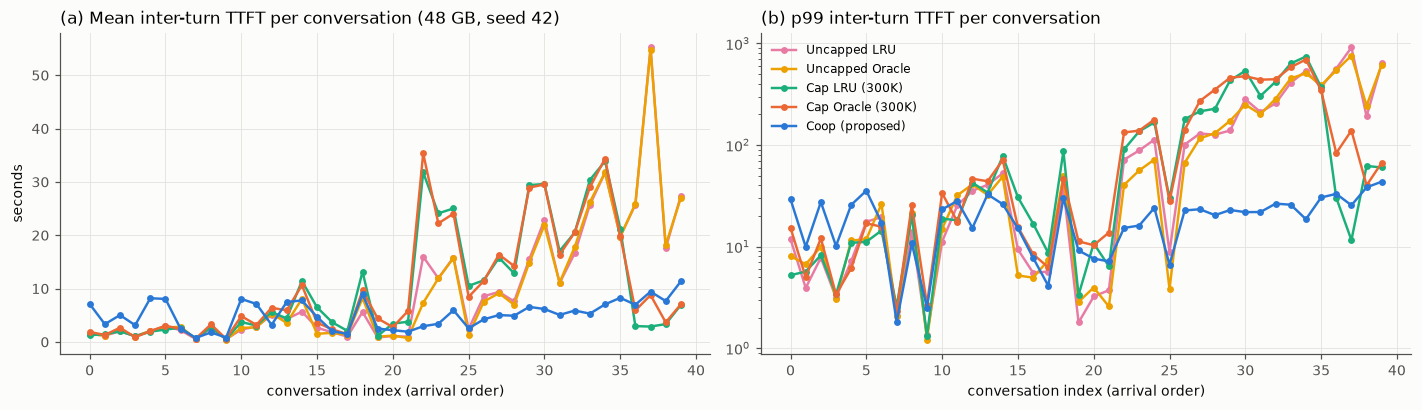

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for n, (R, s) in DIAG.items():
    idx = np.arange(40)
    m = [R[R[:, 5] == i, 0].mean() for i in idx]
    p = [np.percentile(R[R[:, 5] == i, 0], 99) for i in idx]
    axes[0].plot(idx, m, marker="o", ms=3.5, lw=1.6, color=PAL[n], label=n)
    axes[1].plot(idx, p, marker="o", ms=3.5, lw=1.6, color=PAL[n], label=n)
axes[0].set(title="(a) Mean inter-turn TTFT per conversation (48 GB, seed 42)", xlabel="conversation index (arrival order)", ylabel="seconds")
axes[1].set(title="(b) p99 inter-turn TTFT per conversation", xlabel="conversation index (arrival order)", yscale="log")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**What this shows.**

1. For the slowest 1 % of turns, essentially **all** of the TTFT is queueing (hundreds of seconds); PCIe reload stall and the prefill step
   are each a fraction of a second. p99 inter-turn TTFT is an **admission** problem, not a cache-miss problem, on this hardware model.
2. The tail is not random: TTFT grows with conversation index (corr ≈ 0.6–0.76 for the baselines). Because admission walks `self.live` in
   index order, early conversations returning from short tool calls (median 3 s) always jump ahead, and late conversations starve —
   the classic failure of a static priority under overload. vLLM itself enqueues each agent call as a new request (FCFS per *turn*),
   so this is a property of the simulator's program-level ordering, not of vLLM.
3. The cap makes it worse: under a fixed `r_cap` there are fewer slots, so the starved conversations wait longer.

---
## Part 2 — The cooperative algorithm

**Scheduler — reads cache state** (`CoopSchedulerMixin`)

```
every reconcile tick:
    order = waiting turns sorted by
              urgent first  (urgent  ⇔  now − ready_at ≥ D)      — oldest first
              then base order (program index; or ready_at + w·start_cost)   start_cost = DRAM reload time + uncached prefill
    for turn in order:
        if an urgent turn is blocked on HBM and this turn needs new blocks (and is not urgent): skip   # reserve HBM for it
        admit if it fits HBM and
                 (urgent  → soft cap: may exceed r_cap; bounded only by HBM)
                 (else    → obeys r_cap)
        on failure: continue (backfill) instead of break
```

**Replacement — reads scheduler state** (`CoopReplacementMixin`, built on the Paged-Oracle machinery)

```
next_use(conv) = τ_tool_return + q̂                     if TOOL       q̂ = EWMA of queueing delay
               = now + rank_in_admission_order · ĥ       if WAITING    ĥ = EWMA of inter-admission gap
victim = argmax next_use   (evict tail blocks only; the next K=4 turns the scheduler will admit are evicted only as a last resort)
JIT reloads: as Paged Oracle, but a victim must be used later than the reloading turn's own next use
prefetch:   offloaded blocks of WAITING turns among the next K=4 to be admitted are reloaded into free HBM while they queue
```

**How decisions differ from the baselines**

| decision | Cap LRU / Cap Oracle | Uncapped LRU / Oracle | Coop |
|---|---|---|---|
| admission order | program index, stop at first failure | same | urgent-by-age first, then program index; backfill |
| concurrency | hard `r_cap` = 300K active tokens | none (HBM only) | `r_cap` for young turns; urgent turns bypass it |
| eviction ranking | LRU / furthest τ (WAITING only as fallback) | same | predicted next use incl. queue position; head of queue protected |
| reload timing | reactive / JIT at τ | same | JIT + prefetch for turns about to be admitted |

Knobs were chosen on **dev seeds 100–101** (D = 1 s, K = 4); all results below use **held-out seeds 1–5 + 42**. Every feature has a flag;
with all flags off `CoopSim` is bit-identical to `CappedPagedOracleSim` (checked).

Dropped during design (dev seeds, refuted): bounding the urgent overflow at 0.85·HBM (`r_hard`) made p99 *worse* (~55 s vs ~28 s at
48 GB) — it only moves the blocking from HBM to the cap; strict / drain HBM reservation for a blocked urgent turn did not help either.

---
## Part 3 — Main comparison (identical workloads, seeds, HBM, hardware)

Uncapped LRU = `NaivePagedLRUSim`, Uncapped Oracle = `PagedOracleSim`, Cap LRU / Cap Oracle = the capped variants with the notebook's
selected `R_bw* = 300K`. Mean over 6 held-out seeds; λ = 0.15; n = 40 conversations.

In [5]:
COLS = [("p50", lambda s: s["ttft_p50"], "{:6.2f}"), ("p95", lambda s: s["ttft_p95"], "{:6.1f}"),
        ("p99", lambda s: s["ttft_p99"], "{:6.1f}"), ("max", cm("ttft_max"), "{:6.0f}"),
        ("E2E", lambda s: s["mean_e2e_s"], "{:6.0f}"), ("tok/s", cm("throughput_tok_s"), "{:6.1f}"),
        ("conv/h", cm("throughput_conv_hr"), "{:6.1f}"),
        ("qMean", cm("mean_queue"), "{:6.1f}"), ("qP99", cm("queue_p99"), "{:6.1f}"),
        ("1stW", cm("first_turn_wait_mean"), "{:6.1f}"),
        ("D2H GB", cm("pcie_d2h_gb"), "{:6.0f}"), ("H2D GB", cm("pcie_h2d_gb"), "{:6.0f}"),
        ("reloads", lambda s: s["total_reloads"], "{:6.0f}"),
        ("B mean", cm("active_batch_mean"), "{:6.1f}"), ("B p95", cm("active_batch_p95"), "{:6.0f}"),
        ("Ract K", lambda s: s["coop_metrics"].get("active_resident_tok_mean", 0) / 1e3, "{:6.0f}"),
        ("preempt", cm("preemptions"), "{:6.0f}")]

def table(exp, hbm, labs=None, rate=0.15):
    labs = labs or labels(exp)
    print(f"--- {exp}: {hbm:.0f} GB, λ={rate} (mean over seeds {SEEDS}) ---")
    print(f"{'policy':32s} " + " ".join(f"{h:>7s}" for h, _, _ in COLS) + "  p99 sd")
    for lab in labs:
        ss, _ = runs(exp, lab, hbm, rate)
        if not ss:
            continue
        assert all(s["done"] == s["total_requests"] for s in ss), lab
        print(f"{lab:32s} " + " ".join(f"{fmt.format(np.mean([g(s) for s in ss])):>7s}" for _, g, fmt in COLS)
              + f"  {np.std([s['ttft_p99'] for s in ss]):6.1f}")
    print()

for h in HBMS:
    table("main", h, MAIN[::-1])
print("columns: TTFT p50/p95/p99/max (s); mean E2E (s); decode tok/s; conversations/h; queueing mean/p99 (s); first-turn wait (s);\n"
      "PCIe offload/reload volume; reload count; time-weighted active batch (mean, p95); mean active resident tokens; vLLM preemptions")

--- main: 48 GB, λ=0.15 (mean over seeds [1, 2, 3, 4, 5, 42]) ---
policy                               p50     p95     p99     max     E2E   tok/s  conv/h   qMean    qP99    1stW  D2H GB  H2D GB reloads  B mean   B p95  Ract K preempt  p99 sd
Uncapped LRU                        1.00    28.8   119.8     847    1612   101.7    39.0     8.1   119.4    92.1    3334    3304    1302     9.7      19     280       8    49.7
Uncapped Oracle                     0.89    26.6   123.0     892    1613   100.9    38.7     8.2   122.7    88.0    3071    3049    2278     9.7      19     279      12    43.8
Cap LRU (300K)                      1.18    37.4   135.4     961    1649    98.2    37.6     9.8   135.2   222.7    1462    1461     637     7.8      14     227       0    15.7
Cap Oracle (300K)                   1.36    36.6   138.2     827    1659    98.1    37.5     9.9   137.8   227.6    1663    1656     720     7.8      14     226       0     7.0
Coop (proposed)                     2.82    13.7 

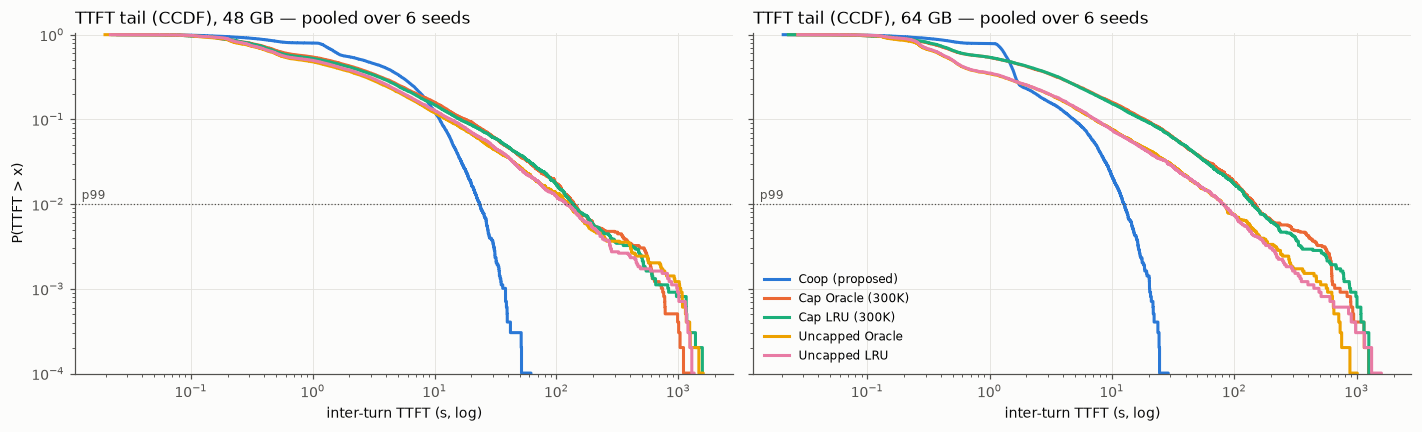

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, hbm in zip(axes, HBMS):
    for lab in MAIN:
        x = np.sort(np.concatenate([r[:, 0] for r in runs("main", lab, hbm)[1]]))
        y = 1 - np.arange(1, len(x) + 1) / len(x)
        ax.step(x, np.maximum(y, 1e-5), where="post", color=PAL[lab], lw=2, label=lab)
    ax.axhline(0.01, color=INK2, lw=0.8, ls=":")
    ax.text(0.01, 0.0115, "p99", color=INK2, fontsize=8, transform=ax.get_yaxis_transform())
    ax.set(xscale="log", yscale="log", ylim=(1e-4, 1.05), xlabel="inter-turn TTFT (s, log)",
           title=f"TTFT tail (CCDF), {hbm:.0f} GB — pooled over 6 seeds")
axes[0].set_ylabel("P(TTFT > x)")
axes[1].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Reading the CCDF.** The four baselines have near-identical heavy tails reaching ~1000 s — eviction policy (LRU vs Oracle) makes no
visible difference. Coop trades a slightly heavier body (more turns wait a second or two: the age guard deliberately holds young turns
behind the cap) for a tail that is cut off at ~40 s (48 GB) / ~20 s (64 GB).

      policy                        total   queue  reload  prefill    step
 48G  Coop (proposed)      mean      4.53    4.12   0.263    0.034   0.115
 48G  Coop (proposed)      top1%    29.39   28.07   1.183    0.025   0.116
 48G  Cap Oracle (300K)    mean     10.15    9.97   0.037    0.034   0.105
 48G  Cap Oracle (300K)    top1%   368.16  367.79   0.145    0.070   0.158
 48G  Cap LRU (300K)       mean     10.03    9.86   0.040    0.034   0.099
 48G  Cap LRU (300K)       top1%   376.84  376.52   0.101    0.052   0.171
 48G  Uncapped Oracle      mean      8.67    8.35   0.160    0.034   0.122
 48G  Uncapped Oracle      top1%   386.56  386.10   0.207    0.057   0.194
 48G  Uncapped LRU         mean      8.47    8.21   0.101    0.034   0.126
 48G  Uncapped LRU         top1%   350.68  350.28   0.122    0.052   0.228
 64G  Coop (proposed)      mean      2.11    1.79   0.151    0.034   0.129
 64G  Coop (proposed)      top1%    15.86   14.51   1.144    0.034   0.168
 64G  Cap Oracle (300K)  

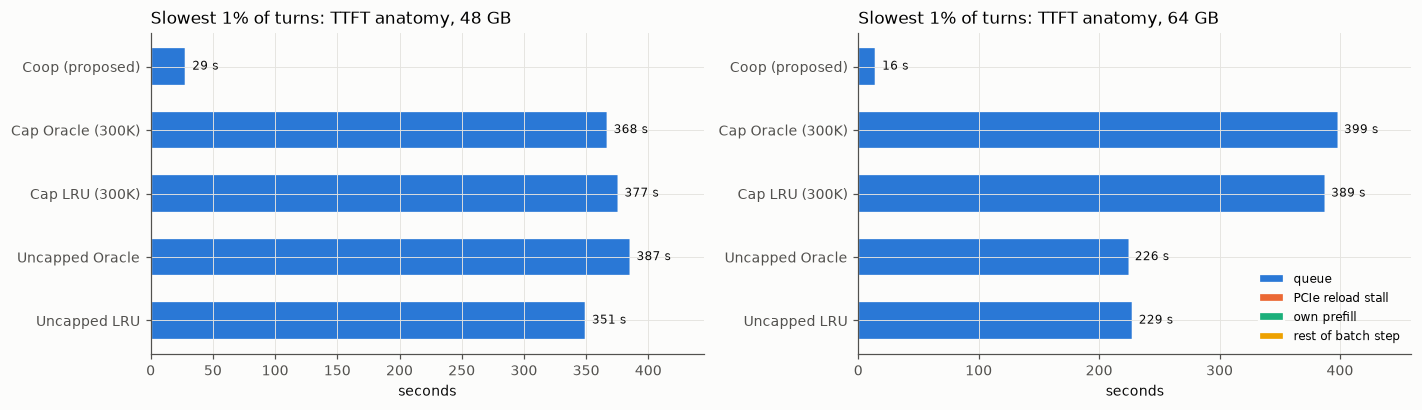

In [7]:
comp = [("queue", "#2a78d6"), ("PCIe reload stall", "#eb6834"), ("own prefill", "#1baf7a"), ("rest of batch step", "#eda100")]
print(f"{'':6s}{'policy':20s} {'':6s} {'total':>7s} {'queue':>7s} {'reload':>7s} {'prefill':>8s} {'step':>7s}")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, hbm in zip(axes, HBMS):
    vals = []
    for lab in MAIN:
        R = np.concatenate(runs("main", lab, hbm)[1])
        for nm, sel in (("mean", np.ones(len(R), bool)), ("top1%", R[:, 0] >= np.percentile(R[:, 0], 99))):
            X = R[sel]
            v = (X[:, 1].mean(), X[:, 2].mean(), X[:, 4].mean(), X[:, 3].mean() - X[:, 4].mean())
            print(f"{hbm:3.0f}G  {lab:20s} {nm:6s} {X[:,0].mean():7.2f} {v[0]:7.2f} {v[1]:7.3f} {v[2]:8.3f} {v[3]:7.3f}")
            if nm == "top1%":
                vals.append(v)
    vals = np.array(vals); bottom = np.zeros(len(MAIN))
    for j, (nm, col) in enumerate(comp):
        ax.barh(range(len(MAIN)), vals[:, j], 0.6, left=bottom, color=col, label=nm, edgecolor=SURF, linewidth=1.5)
        bottom += vals[:, j]
    for i, t in enumerate(bottom):
        ax.text(t + 4, i, f"{t:.0f} s", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(MAIN)), MAIN); ax.invert_yaxis()
    ax.set(title=f"Slowest 1% of turns: TTFT anatomy, {hbm:.0f} GB", xlabel="seconds", xlim=(0, bottom.max() * 1.15))
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

**Anatomy.** The reload / prefill / step segments are invisible at this scale because they are sub-second (see the printed table: reload
stall for Coop's top 1 % is ~1.2 s, larger than the baselines' ~0.1–0.2 s because Coop rotates more conversations through HBM and
prefetches; still negligible next to the queueing it removes). Mean TTFT also drops (≈ 10 s → 4.5 s at 48 GB).

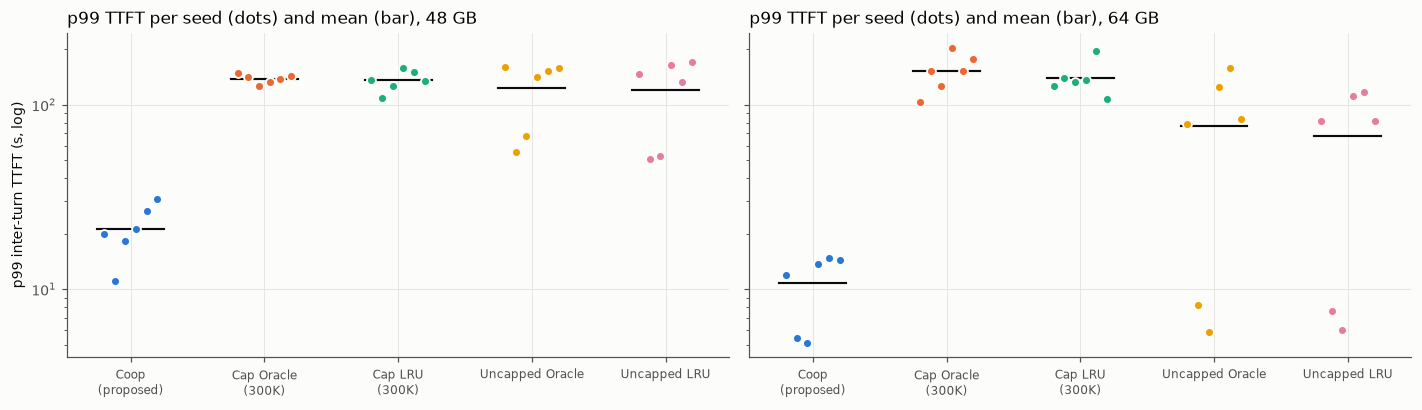

Paired per-seed comparison, Coop vs each baseline:
   48 GB vs Cap Oracle (300K) : p99 ratio geo-mean 0.15 (range 0.08–0.21), lower in 6/6 seeds | mean-E2E ratio 0.968 (range 0.918–1.132)
   48 GB vs Cap LRU (300K)    : p99 ratio geo-mean 0.15 (range 0.10–0.23), lower in 6/6 seeds | mean-E2E ratio 0.972 (range 0.927–1.128)
   48 GB vs Uncapped Oracle   : p99 ratio geo-mean 0.18 (range 0.12–0.27), lower in 6/6 seeds | mean-E2E ratio 0.994 (range 0.943–1.117)
   48 GB vs Uncapped LRU      : p99 ratio geo-mean 0.19 (range 0.13–0.35), lower in 6/6 seeds | mean-E2E ratio 0.995 (range 0.947–1.114)
   64 GB vs Cap Oracle (300K) : p99 ratio geo-mean 0.07 (range 0.04–0.12), lower in 6/6 seeds | mean-E2E ratio 0.920 (range 0.848–1.054)
   64 GB vs Cap LRU (300K)    : p99 ratio geo-mean 0.07 (range 0.04–0.13), lower in 6/6 seeds | mean-E2E ratio 0.924 (range 0.851–1.057)
   64 GB vs Uncapped Oracle   : p99 ratio geo-mean 0.23 (range 0.09–0.87), lower in 6/6 seeds | mean-E2E ratio 0.979 (range 0.9

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, hbm in zip(axes, HBMS):
    for j, lab in enumerate(MAIN):
        ss, _ = runs("main", lab, hbm)
        y = [s["ttft_p99"] for s in ss]
        x = j + (np.arange(len(y)) - (len(y) - 1) / 2) * 0.08
        ax.scatter(x, y, s=34, color=PAL[lab], edgecolor=SURF, linewidth=1.2, zorder=3)
        ax.plot([j - 0.25, j + 0.25], [np.mean(y)] * 2, color=INK, lw=1.4)
    ax.set_xticks(range(len(MAIN)), [m.replace(" (", "\n(") for m in MAIN], fontsize=8)
    ax.set(yscale="log", title=f"p99 TTFT per seed (dots) and mean (bar), {hbm:.0f} GB")
axes[0].set_ylabel("p99 inter-turn TTFT (s, log)")
plt.tight_layout(); plt.show()

print("Paired per-seed comparison, Coop vs each baseline:")
for hbm in HBMS:
    sa = {s["seed"]: s for s in runs("main", "Coop (proposed)", hbm)[0]}
    for b in MAIN[1:]:
        sb = {s["seed"]: s for s in runs("main", b, hbm)[0]}
        r = np.array([sa[k]["ttft_p99"] / sb[k]["ttft_p99"] for k in SEEDS])
        e = np.array([sa[k]["mean_e2e_s"] / sb[k]["mean_e2e_s"] for k in SEEDS])
        print(f"  {hbm:3.0f} GB vs {b:18s}: p99 ratio geo-mean {np.exp(np.log(r).mean()):.2f} (range {r.min():.2f}–{r.max():.2f}), "
              f"lower in {(r < 1).sum()}/{len(r)} seeds | mean-E2E ratio {e.mean():.3f} (range {e.min():.3f}–{e.max():.3f})")

---
## Part 4 — Validation: is it scheduling, replacement, or their interaction?

Each row adds one component on top of Cap Oracle, plus three cross-checks (replacement only, LRU replacement under the Coop scheduler,
and no cap at all).

--- ablation: 48 GB, λ=0.15 (mean over seeds [1, 2, 3, 4, 5, 42]) ---
policy                               p50     p95     p99     max     E2E   tok/s  conv/h   qMean    qP99    1stW  D2H GB  H2D GB reloads  B mean   B p95  Ract K preempt  p99 sd
A0 Cap Oracle                       1.36    36.6   138.2     827    1659    98.1    37.5     9.9   137.8   227.6    1663    1656     720     7.8      14     226       0     7.0
A1 +backfill                        2.08    62.3   211.6     679    1659   100.7    38.6    13.8   210.8    35.4    2371    2362     968     8.1      15     234       0    79.6
A2 +age guard (hard cap)           13.33    38.2    51.1      78    1676   101.4    39.1    15.0    50.7     2.6    3655    3638    1526     8.2      15     234       0     9.9
A3 +soft cap = sched only           2.53    13.2    20.0      36    1617   100.9    38.9     3.8    18.9     1.5    3667    3644    4067     9.6      19     274      15     3.1
A4 repl only (cap oracle sched)     1.36    3

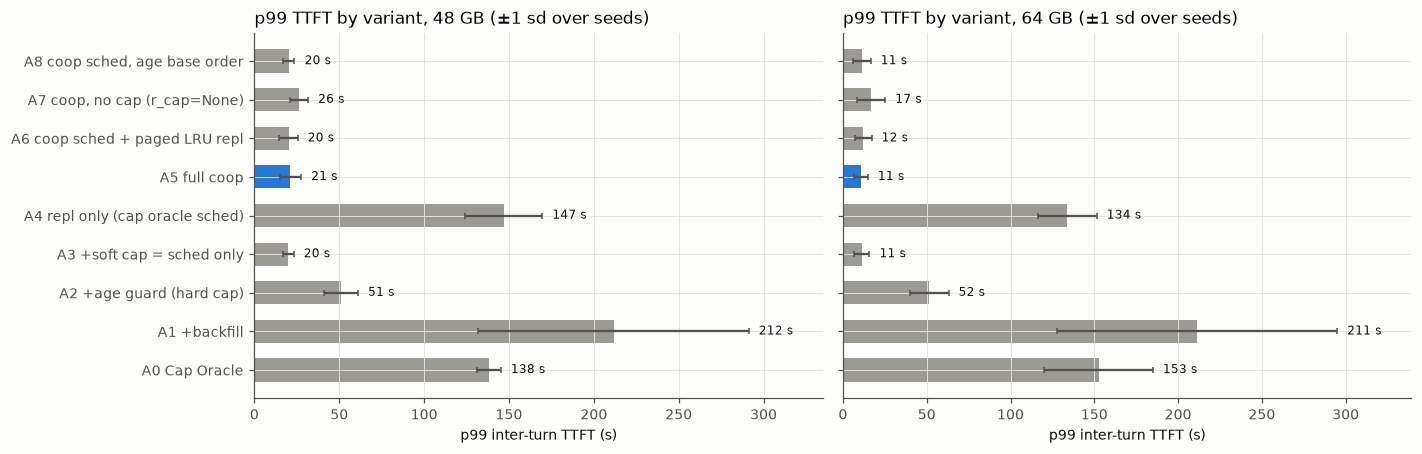

In [9]:
ABL = labels("ablation")
for h in HBMS:
    table("ablation", h, ABL)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, hbm in zip(axes, HBMS):
    m = [mean_of("ablation", a, hbm, lambda s: s["ttft_p99"]) for a in ABL]
    sd = [np.std([s["ttft_p99"] for s in runs("ablation", a, hbm)[0]]) for a in ABL]
    cols = ["#2a78d6" if a.startswith("A5") else "#9b9a95" for a in ABL]
    ax.barh(range(len(ABL)), m, 0.6, xerr=sd, color=cols, ecolor=INK2, capsize=2)
    for i, v in enumerate(m):
        ax.text(v + sd[i] + 6, i, f"{v:.0f} s", va="center", fontsize=8, color=INK)
    ax.set_yticks(range(len(ABL)), ABL); ax.invert_yaxis()
    ax.set(title=f"p99 TTFT by variant, {hbm:.0f} GB (±1 sd over seeds)", xlabel="p99 inter-turn TTFT (s)",
           xlim=(0, max(v + e for v, e in zip(m, sd)) * 1.15))
plt.tight_layout(); plt.show()

**What the ablation says.**

* **Replacement alone does nothing** (A4 ≈ A0): queue-aware eviction + prefetch under the baseline scheduler leaves p99 at ~135–150 s.
* **The scheduler is the whole effect** (A3 ≈ A5): Coop scheduling with the *unchanged* Paged-Oracle replacement gets 20 s / 11 s;
  with plain Paged-**LRU** replacement (A6) it gets the same within seed noise. Replacement-side cooperation's measurable contribution is a
  ~17 % PCIe reduction at 64 GB vs LRU (2.0 TB vs 2.4 TB D2H), not TTFT.
* **Within the scheduler, the components interact:**
  * backfill alone (A1) makes p99 *worse* (≈ 211 s): small/resident turns jump ahead and large turns starve longer;
  * the age guard with a *hard* cap (A2) fixes starvation but makes everyone wait for a cap slot (p99 ≈ 51 s, p50 ≈ 13 s);
  * letting urgent turns bypass the cap (A3) is what collapses the tail.
* **Removing the cap entirely (A7) is worse** than the soft cap (26 vs 21 s; 17 vs 11 s) — see Part 6 for why.
* Base order (program index vs age, A8) does not matter once the age guard is in.

---
## Part 5 — Can a fixed cap or a different age guard match it? (Pareto view)

Fixed caps from 200K to 400K active tokens (both replacement policies) vs the age-guard sweep D ∈ {0, 1, 2.5, 5, 10, 20, 40, 80} s.

In [10]:
for h in HBMS:
    table("capsweep", h)
for h in HBMS:
    table("dsweep", h)

--- capsweep: 48 GB, λ=0.15 (mean over seeds [1, 2, 3, 4, 5, 42]) ---
policy                               p50     p95     p99     max     E2E   tok/s  conv/h   qMean    qP99    1stW  D2H GB  H2D GB reloads  B mean   B p95  Ract K preempt  p99 sd
Cap Oracle 200K                     1.82    51.6   189.8     629    1824    91.6    35.0    12.5   189.5   465.1     546     545     278     5.5       9     159       0    48.9
Cap Oracle 250K                     1.48    41.9   134.7     837    1702    96.0    36.7    10.3   134.5   345.5     921     919     434     6.7      12     193       0    34.5
Cap Oracle 350K                     0.98    33.7   123.5     924    1619   100.2    38.4     8.9   123.2   140.7    2250    2240     964     8.9      17     258       0    22.0
Cap Oracle 400K                     0.85    28.7   113.8     949    1607   101.1    38.8     8.0   113.3    91.7    3054    3035    1386     9.7      19     280       8    49.6
Cap LRU 200K                        1.81    5

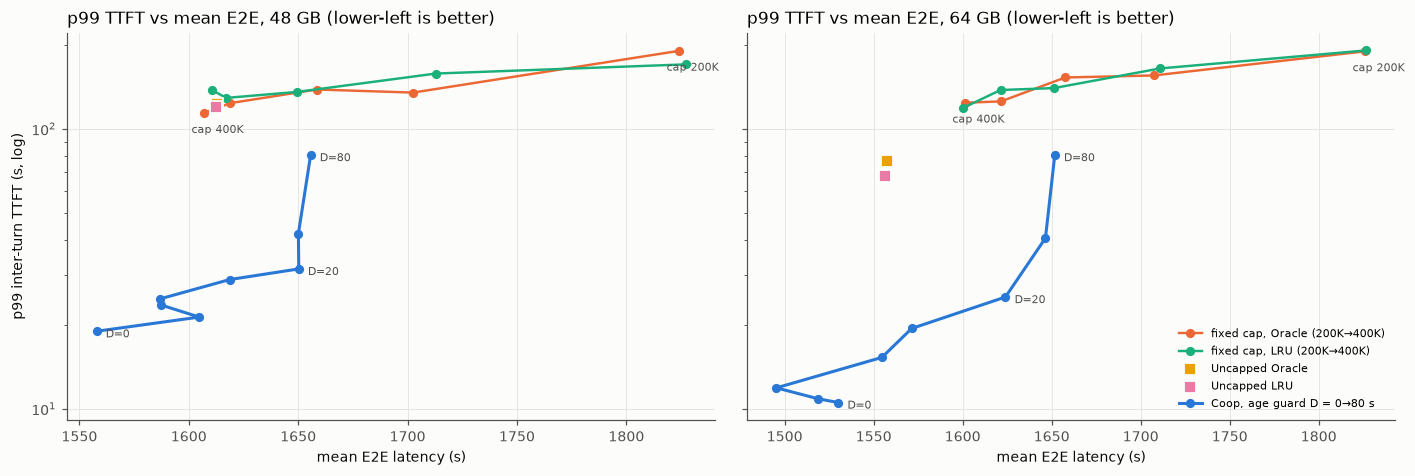

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
caps = [200, 250, 300, 350, 400]
ds = [0, 1, 2.5, 5, 10, 20, 40, 80]
for ax, hbm in zip(axes, HBMS):
    for kind, col in (("Oracle", PAL["Cap Oracle (300K)"]), ("LRU", PAL["Cap LRU (300K)"])):
        labs = [("main", f"Cap {kind} (300K)") if c == 300 else ("capsweep", f"Cap {kind} {c}K") for c in caps]
        x = [mean_of(e, l, hbm, lambda s: s["mean_e2e_s"]) for e, l in labs]
        y = [mean_of(e, l, hbm, lambda s: s["ttft_p99"]) for e, l in labs]
        ax.plot(x, y, marker="o", ms=5, lw=1.6, color=col, label=f"fixed cap, {kind} (200K→400K)")
        for xi, yi, c in zip(x, y, caps):
            if kind == "Oracle" and c in (200, 400):
                ax.annotate(f"cap {c}K", (xi, yi), textcoords="offset points", xytext=(-8, -13), fontsize=7.5, color=INK2)
    for lab in ("Uncapped Oracle", "Uncapped LRU"):
        ax.scatter(mean_of("main", lab, hbm, lambda s: s["mean_e2e_s"]), mean_of("main", lab, hbm, lambda s: s["ttft_p99"]),
                   s=60, marker="s", color=PAL[lab], edgecolor=SURF, linewidth=1.2, zorder=4, label=lab)
    x = [mean_of("dsweep", f"Coop D={d:g}", hbm, lambda s: s["mean_e2e_s"]) for d in ds]
    y = [mean_of("dsweep", f"Coop D={d:g}", hbm, lambda s: s["ttft_p99"]) for d in ds]
    ax.plot(x, y, marker="o", ms=5, lw=2, color=PAL["Coop (proposed)"], label="Coop, age guard D = 0→80 s")
    for xi, yi, d in zip(x, y, ds):
        if d in (0, 20, 80):
            ax.annotate(f"D={d:g}", (xi, yi), textcoords="offset points", xytext=(6, -4), fontsize=7.5, color=INK2)
    ax.set(yscale="log", xlabel="mean E2E latency (s)", title=f"p99 TTFT vs mean E2E, {hbm:.0f} GB (lower-left is better)")
axes[0].set_ylabel("p99 inter-turn TTFT (s, log)")
axes[1].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.show()

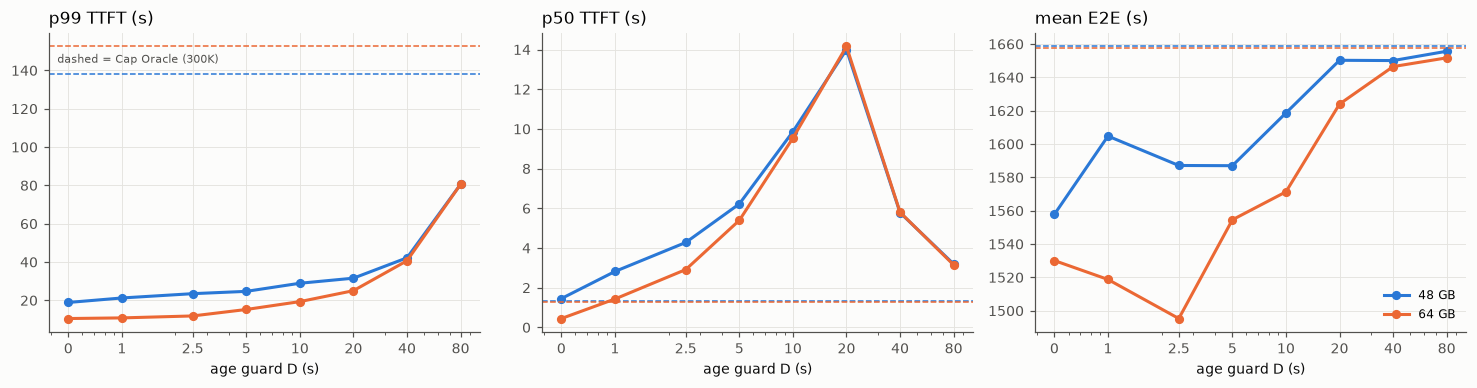

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
hcol = {48.0: "#2a78d6", 64.0: "#eb6834"}
xs = [0.5] + ds[1:]
for hbm in HBMS:
    for ax, f, nm in ((axes[0], lambda s: s["ttft_p99"], "p99 TTFT (s)"), (axes[1], lambda s: s["ttft_p50"], "p50 TTFT (s)"),
                      (axes[2], lambda s: s["mean_e2e_s"], "mean E2E (s)")):
        ax.plot(xs, [mean_of("dsweep", f"Coop D={d:g}", hbm, f) for d in ds], marker="o", ms=5, lw=2, color=hcol[hbm], label=f"{hbm:.0f} GB")
        ax.axhline(mean_of("main", "Cap Oracle (300K)", hbm, f), color=hcol[hbm], lw=1, ls="--")
        ax.set_xscale("log"); ax.set_xticks(xs, ["0"] + [f"{d:g}" for d in ds[1:]]); ax.set(xlabel="age guard D (s)", title=nm)
axes[2].legend(fontsize=8); axes[0].text(0.02, 0.9, "dashed = Cap Oracle (300K)", transform=axes[0].transAxes, fontsize=7.5, color=INK2)
plt.tight_layout(); plt.show()

**Pareto reading.**

* No fixed cap gets anywhere near: the best fixed cap's p99 is ~114 s (400K) — raising the cap trades a bit of p99 for E2E but the
  starvation tail stays, because the *ordering* is the problem, not the cap value.
* The age guard D is a clean dial: p99 ≈ D + (time to drain a slot). p50 rises with D up to ~20 s (young turns are held behind the cap
  until they turn urgent) and falls again for D ≥ 40 s, where the policy degenerates towards the capped baseline with a hard deadline.
* **Honest note on tuning.** D = 1 s was picked on dev seeds 100–101. On the held-out seeds D = 0 is slightly better on every metric
  (48 GB: p99 18.9 vs 21.3 s, p50 1.45 vs 2.82 s, E2E 1558 vs 1605 s). We report D = 1 as "proposed" rather than re-tuning on test data;
  the difference is within ~1 seed-sd for p99.

---
## Part 6 — Why the soft cap still matters at D = 0

At D = 0 every turn with a ready time is urgent, so the cap can only bind on turns *without* one — and the only such turns are
**preempted** ones (decode-phase turns that vLLM-style recompute preemption pushed back to WAITING when decode growth found no block).

--- capcheck: 48 GB, λ=0.15 (mean over seeds [1, 2, 3, 4, 5, 42]) ---
policy                               p50     p95     p99     max     E2E   tok/s  conv/h   qMean    qP99    1stW  D2H GB  H2D GB reloads  B mean   B p95  Ract K preempt  p99 sd
D0 + soft cap 300K                  1.45    12.0    18.9      33    1558   101.2    38.9     3.0    17.9     1.2    3270    3246    4219     9.7      19     274      14     2.8
D0, no cap                          3.87    16.2    23.4      38    1586   103.1    39.7     4.9    22.0     1.2    3979    3947    5358    10.1      20     289      22     3.9
turn-FIFO, no cap                   9.13    25.6    34.7      45    1605   102.1    39.4     9.9    34.3     1.5    4203    4184    1987     9.8      19     281       7    11.9
turn-FIFO, no cap, backfill         7.37    26.2    36.4      54    1609   102.3    39.4     9.0    35.0     1.3    4192    4153    5602    10.1      20     288      27    12.9
turn-FIFO + hard cap 300K          15.42    3

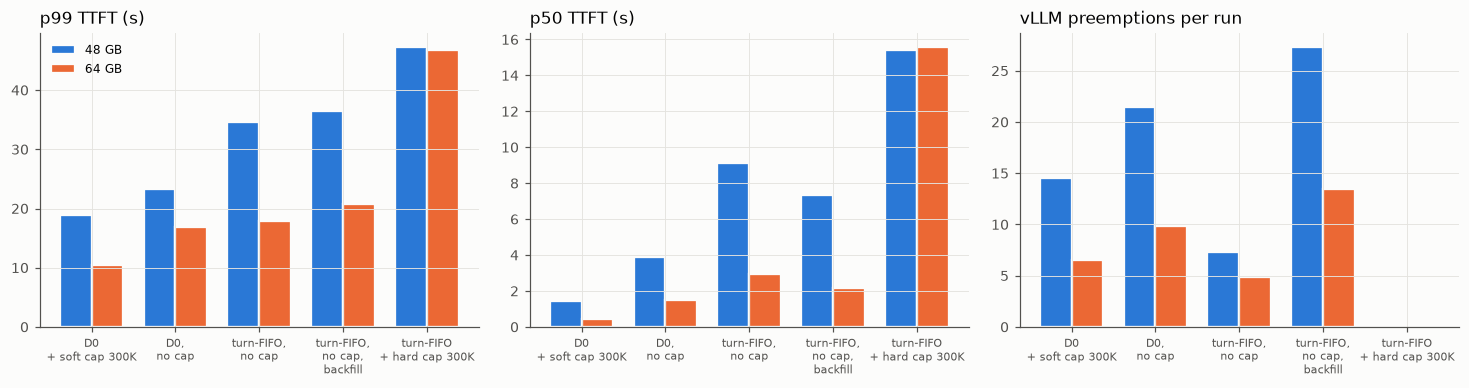

In [13]:
CC = labels("capcheck")
for h in HBMS:
    table("capcheck", h, CC)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
for ax, (f, nm) in zip(axes, ((lambda s: s["ttft_p99"], "p99 TTFT (s)"), (lambda s: s["ttft_p50"], "p50 TTFT (s)"),
                              (cm("preemptions"), "vLLM preemptions per run"))):
    w = 0.38
    for k, hbm in enumerate(HBMS):
        v = [mean_of("capcheck", c, hbm, f) for c in CC]
        ax.bar(np.arange(len(CC)) + (k - 0.5) * w, v, w, color=hcol[hbm], label=f"{hbm:.0f} GB", edgecolor=SURF, linewidth=1.5)
    ax.set_xticks(range(len(CC)), [c.replace(", ", ",\n").replace(" + ", "\n+ ") for c in CC], fontsize=7)
    ax.set(title=nm)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mechanism (verified with a probe during development, seed 1, 48 GB):** with the cap, every non-urgent queue entry at D = 0 was a
preempted turn; holding them behind `r_cap` instead of re-admitting them straight into a full HBM cut preemptions 22 → 13, time spent in
full-context re-prefill steps (> 10K prefill tokens) 85 → 72 s, and mean queueing of fresh turns 5.0 → 3.2 s. Because those preempted
turns already emitted their first token, one might suspect metric gaming — but mean E2E does not get worse: it improves at 48 GB
(1586 → 1558 s) and is within noise at 64 GB (1521 → 1530 s), so this is a genuine throttling of preemption cascades rather than
pushing delay outside the metric. Pure turn-FIFO without any cap (with or without backfill) is clearly worse on both p50 and p99.

---
## Part 7 — Costs and robustness

**PCIe traffic and concurrency.** Fair service rotates *all* conversations through HBM instead of letting a stable low-index subset stay
resident, so offload/reload volume rises vs the capped baselines (and slightly vs uncapped). Active concurrency rises to the uncapped level.

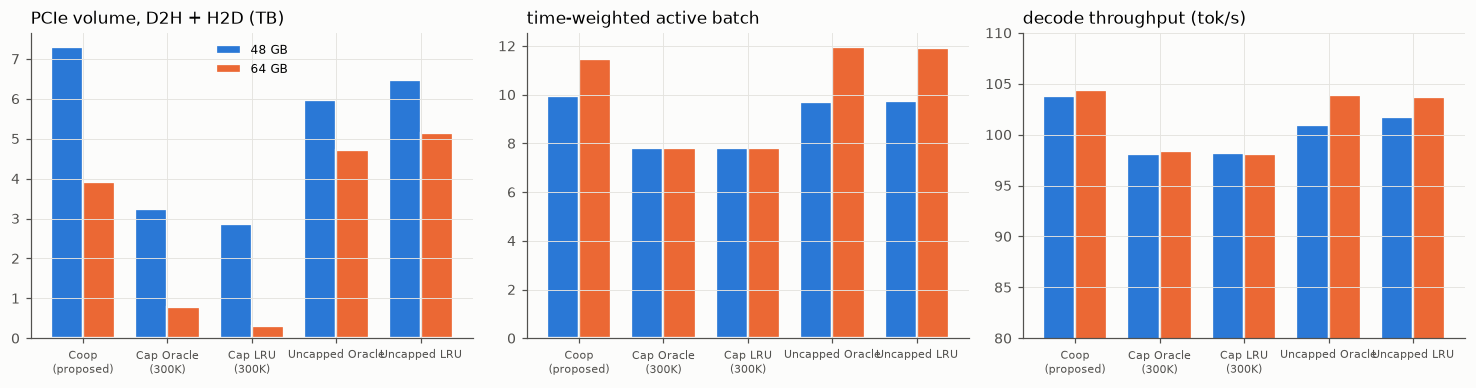

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
w = 0.38
for ax, (f, nm) in zip(axes, ((lambda s: (s["coop_metrics"]["pcie_d2h_gb"] + s["coop_metrics"]["pcie_h2d_gb"]) / 1024, "PCIe volume, D2H + H2D (TB)"),
                              (cm("active_batch_mean"), "time-weighted active batch"),
                              (cm("throughput_tok_s"), "decode throughput (tok/s)"))):
    for k, hbm in enumerate(HBMS):
        v = [mean_of("main", lab, hbm, f) for lab in MAIN]
        ax.bar(np.arange(len(MAIN)) + (k - 0.5) * w, v, w, color=hcol[hbm], label=f"{hbm:.0f} GB", edgecolor=SURF, linewidth=1.5)
    ax.set_xticks(range(len(MAIN)), [m.replace(" (", "\n(") for m in MAIN], fontsize=7.5); ax.set(title=nm)
axes[2].set_ylim(80, 110); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
for h in HBMS:
    table("rate025", h, MAIN[::-1], rate=0.25)

--- rate025: 48 GB, λ=0.25 (mean over seeds [1, 2, 3, 4, 5, 42]) ---
policy                               p50     p95     p99     max     E2E   tok/s  conv/h   qMean    qP99    1stW  D2H GB  H2D GB reloads  B mean   B p95  Ract K preempt  p99 sd
Uncapped LRU                        1.18    29.7   144.3     984    1643   101.7    39.0     9.1   143.9    65.7    3519    3493    1378     9.9      19     284      10    70.0
Uncapped Oracle                     1.09    28.2   135.4     962    1646   101.9    39.1     8.8   134.9    77.9    3284    3261    2429     9.9      19     284      12    58.2
Cap LRU (300K)                      1.36    36.4   158.2     896    1689    98.8    37.8    10.1   157.8   246.3    1539    1537     665     7.9      14     228       0    39.3
Cap Oracle (300K)                   1.46    40.3   162.7     891    1696    98.8    37.8    10.3   162.5   239.6    1710    1706     751     7.9      14     229       0    29.4
Coop (proposed)                     3.50    13

**Arrival rate 0.25/s** reproduces the same picture (p99 22 s vs 163 s at 48 GB; 11 s vs 166 s at 64 GB vs Cap Oracle).

---
## Part 8 — Conclusions and caveats

1. **The proposed cooperative policy improves p99 inter-turn TTFT over capped LRU and capped Oracle by 6–14×**, on every held-out seed,
   at both HBM sizes and both arrival rates, while also improving mean E2E (3–8 %) and throughput slightly. The cost is ~+1.5 s p50 at 48 GB
   and 2–5× more PCIe traffic than the capped baselines.
2. **The improvement comes from scheduling, not replacement.** On this hardware model a KV miss costs ~0.1 s of PCIe; the tail is minutes
   of queueing caused by index-ordered admission under a cap. Queue-aware eviction + prefetch measurably reduce PCIe volume vs LRU at 64 GB
   but do not move TTFT.
3. **The interaction that matters is inside the scheduler:** age guard × soft cap × backfill. Each alone is neutral or harmful.
   Concurrency control helps the tail mainly by throttling preempted turns (damping preemption cascades), not by speeding up decode.

**Caveats / threats to validity**
* Replacement cooperation is likely to matter when reloads are expensive (slower or contended PCIe, CXL/SSD tiers). We did **not** change
  the calibrated hardware model; a clearly labelled sensitivity study would be the next experiment.
* D was tuned on dev seeds; held-out data prefers D = 0 slightly.
* Workload: one trace family (Exgentic SWE-bench), n = 40 conversations sampled with replacement; 6 seeds; ~1700–2000 TTFT samples per run.
* Simulator artifacts that affect all policies equally: 0.5 s admission epoch (p50 floor); after a *reactive* reload the KV holds no HBM
  blocks until admission; no chunked prefill (`max_batched_tokens = 0`).

**Reproduce:** `python3.11 sim/run_coop_experiments.py` (~22 min on 96 cores) → `results/coop/`; this notebook only reads those files,
except Part 1b which re-runs 5 simulations (~1.5 min).